In [7]:
import os, collections, sys
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()
ROOT = os.getenv('PROJECT_ROOT')

EMB_DIR  = f'{ROOT}/datasets/pp/celeba/embeddings_facenet'   # 202,602 Facenet512 embeddings (512-d)
IDENTITY = f'{ROOT}/datasets/pp/celeba/identity_CelebA.txt'  # lines: "<img>.jpg <identity_int>"

# ---- ourfe (our defense): decode-first Leech codeword + per-block keyed BLAKE2b hash (or universal hash) ----
sys.path.insert(0, f'{ROOT}/PIPE_attack/datagen')
from leech_helper import _preprocess, _to_int, _decode_vector_int, _vector_hash, DIM
import datagen_ourdef as odg                      # ourfe gen/rep semantics (ss_gen seeds keys by id)

SCALE = odg.FACENET_SCALE                          # ourfe operating scale (decode-first leech)
NBLK  = 504 // DIM                                 # 21 blocks of 24
BT    = 4                                          # verify at >= 4 of 21 keyed-hash blocks


def decode_codeword(e):
    """ourfe gen step: decode a 512-d embedding to its 504-d Leech codeword (21 blocks of 24)."""
    return _decode_vector_int(_to_int(_preprocess(np.asarray(e, np.float64)), scale=SCALE))[0]


def keys_for(iden):
    """per-identity keyed-hash keys, seeded by identity (== ourfe ss_gen: np.random.seed(id))."""
    return np.random.RandomState(int(iden)).randint(0, 2 ** 32, size=NBLK)


def verify(enroll_wc, keys, probe_wcs):
    """ourfe authentication: enrolment hashes c1 = keyed_hash(decode(e_enroll), keys); a probe
    verifies iff its recomputed keyed hash (same keys) matches c1 in >= BT of 21 blocks. The
    keyed hash is injective per block, so this is exactly the decode-first Leech recovery
    (== eval_protected / tpr_fpr ourfe). Returns a bool array, one per probe codeword."""
    c1 = np.asarray(_vector_hash(enroll_wc, keys))
    return np.array([int((np.asarray(_vector_hash(p, keys)) == c1).sum()) >= BT
                     for p in np.atleast_2d(probe_wcs)])


print(f'ourfe: scale={SCALE}  blocks={NBLK}  verify >= {BT}/{NBLK}  (decode-first keyed-hash)')

ourfe: scale=144.64  blocks=21  verify >= 4/21  (decode-first keyed-hash)


In [8]:
# ---- 100 celeba identities with the most images ----
img2id = {}
for line in open(IDENTITY):
    p = line.split()
    if len(p) == 2:
        img2id[p[0]] = int(p[1])                  # '000001.jpg' -> identity int
by_id = collections.defaultdict(list)
for img, iden in img2id.items():
    by_id[iden].append(img)

k = 1000
topk = [iden for iden, _ in
         collections.Counter({i: len(v) for i, v in by_id.items()}).most_common(k)]

# load each person's Facenet512 embeddings (skip any image lacking a saved embedding)
people = {}                                       # id -> (N_i, 512) raw embeddings
for iden in topk:
    embs = [np.load(f'{EMB_DIR}/{img[:-4]}.npy').astype(np.float64).flatten()
            for img in by_id[iden] if os.path.exists(f'{EMB_DIR}/{img[:-4]}.npy')]
    people[iden] = np.stack(embs)

# ourfe gen: decode each image to its Leech codeword (verify() works on these) + per-id keys
Wc   = {i: np.stack([decode_codeword(e) for e in people[i]]) for i in topk}   # id -> (N_i, 504)
keys = {i: keys_for(i) for i in topk}
print(f'top-{k} identities (#images):', {i: len(people[i]) for i in topk})
print('total images:', sum(len(people[i]) for i in topk))

top-1000 identities (#images): {2820: 35, 3782: 35, 3227: 35, 3745: 34, 3699: 34, 8968: 32, 9152: 32, 9256: 32, 4262: 31, 4887: 31, 6568: 31, 1757: 31, 2114: 31, 9840: 31, 4126: 31, 4740: 31, 4978: 31, 2880: 30, 2937: 30, 8692: 30, 5805: 30, 4153: 30, 9040: 30, 6369: 30, 3332: 30, 7081: 30, 1854: 30, 4905: 30, 2464: 30, 6642: 30, 9290: 30, 3670: 30, 1603: 30, 5512: 30, 3272: 30, 4407: 30, 5239: 30, 2079: 30, 4125: 30, 6318: 30, 9177: 30, 4310: 30, 1446: 30, 3896: 30, 8443: 30, 545: 30, 10144: 30, 2879: 30, 6204: 30, 3316: 30, 1499: 30, 1175: 30, 5127: 30, 6145: 30, 5578: 30, 5472: 30, 4876: 30, 7399: 30, 4960: 30, 6746: 30, 4988: 30, 273: 30, 4323: 30, 1946: 30, 5794: 30, 8833: 30, 3325: 30, 4731: 30, 7256: 30, 6802: 30, 3705: 30, 7541: 30, 4225: 30, 59: 30, 7222: 30, 5173: 30, 6679: 30, 5609: 30, 2522: 30, 5151: 30, 5787: 30, 8776: 30, 3485: 30, 4099: 30, 6565: 30, 800: 30, 5311: 30, 1435: 30, 6282: 30, 3055: 30, 4328: 30, 2463: 30, 78: 30, 6844: 30, 5189: 30, 9341: 30, 4258: 30, 7367

In [9]:
# ---- single-probe baseline: enroll image 0 of each person, then verify the rest one at a time ----
# This is plain ourfe (one template, one probe) and it is also the K=1 case of the majority vote.
# genuine = the SAME person's other images;  impostor = the OTHER people's images.
gen_pools = {p: verify(Wc[p][0], keys[p], Wc[p][1:]) for p in topk}                       # bool[N_p-1]
imp_pools = {p: {q: verify(Wc[p][0], keys[p], Wc[q]) for q in topk if q != p} for p in topk}

print('per-person   TPR (genuine)   FPR (impostor)    #gen  #imp')
gen_hits = gen_tot = imp_hits = imp_tot = 0
for p in topk:
    g = gen_pools[p]
    i = np.concatenate(list(imp_pools[p].values()))
    print(f'  id {p:>5}:    {g.mean()*100:6.1f}%         {i.mean()*100:6.2f}%       {len(g):4d}  {len(i):5d}')
    gen_hits += g.sum(); gen_tot += len(g); imp_hits += i.sum(); imp_tot += len(i)

TPR, FPR = gen_hits / gen_tot, imp_hits / imp_tot
print(f'\nSINGLE-PROBE    TPR = {TPR*100:.2f}%  ({gen_hits}/{gen_tot})    '
      f'FPR = {FPR*100:.2f}%  ({imp_hits}/{imp_tot})')

per-person   TPR (genuine)   FPR (impostor)    #gen  #imp
  id  2820:     100.0%           7.83%         34  30003
  id  3782:      26.5%           6.21%         34  30003
  id  3227:      97.1%           3.44%         34  30003
  id  3745:      36.4%           3.93%         33  30004
  id  3699:      90.9%           1.88%         33  30004
  id  8968:      96.8%           5.27%         31  30006
  id  9152:      87.1%           2.40%         31  30006
  id  9256:      80.6%           2.54%         31  30006
  id  4262:      90.0%           4.99%         30  30007
  id  4887:      86.7%           3.60%         30  30007
  id  6568:      80.0%           2.91%         30  30007
  id  1757:      36.7%           4.93%         30  30007
  id  2114:      96.7%           6.27%         30  30007
  id  9840:      83.3%           2.87%         30  30007
  id  4126:      96.7%           3.62%         30  30007
  id  4740:     100.0%           9.51%         30  30007
  id  4978:      93.3%        

In [10]:
# ---- majority voting: ONE enrolment, present K PROBE images, ACCEPT iff a majority verify ----
# Multi-AUTH (this notebook) instead of multi-ENROLL: the template side is plain ourfe -- image 0
# hashed once under the single identity-seeded key set keys[p], no per-enrollment keys -- and it is
# the AUTHENTICATION that is repeated. The claimant supplies K images, each is checked against that
# one template, and the verifier accepts on a strict majority of the K decisions.
#   genuine txn : K draws from the SAME person's other images   -> gen_pools[p]
#   impostor txn: K draws from ONE other person's images        -> imp_pools[p][q], i.e. an attacker
#     presenting K of their own faces. The K votes are correlated through the fixed (victim p,
#     attacker q) pair, so the vote cannot average away a pair that systematically collides.
rng = np.random.default_rng(0)
Ks, R_GEN, R_IMP = [i for i in range(1, 26, 2)], 300, 30        # reps per person / per (victim, attacker)

def majority_rate(pool, K, reps):
    """Number of `reps` transactions accepted, each = majority of K draws from `pool` (bool)."""
    acc = 0
    for _ in range(reps):
        s = pool[rng.choice(len(pool), K, replace=len(pool) < K)]
        acc += int(s.sum() * 2 > K)               # strict majority (> K/2)
    return acc

rows = []
for K in Ks:
    g_acc = g_n = i_acc = i_n = 0
    for p in topk:
        g_acc += majority_rate(gen_pools[p], K, R_GEN); g_n += R_GEN     # K probes of p vs p's template
        for q, vote in imp_pools[p].items():                             # one attacker identity per txn
            i_acc += majority_rate(vote, K, R_IMP); i_n += R_IMP         # K probes of q vs p's template
    rows.append((K, g_acc / g_n, i_acc / i_n))
    print(f'K={K:>2}:  TPR_maj = {g_acc/g_n*100:6.2f}%    FPR_maj = {i_acc/i_n*100:7.3f}%'
          f'    ({g_n} genuine / {i_n} impostor txns)')

K= 1:  TPR_maj =  85.14%    FPR_maj =   4.613%    (300000 genuine / 29970000 impostor txns)
K= 3:  TPR_maj =  89.67%    FPR_maj =   2.569%    (300000 genuine / 29970000 impostor txns)
K= 5:  TPR_maj =  91.20%    FPR_maj =   2.018%    (300000 genuine / 29970000 impostor txns)
K= 7:  TPR_maj =  91.91%    FPR_maj =   1.769%    (300000 genuine / 29970000 impostor txns)
K= 9:  TPR_maj =  92.41%    FPR_maj =   1.630%    (300000 genuine / 29970000 impostor txns)
K=11:  TPR_maj =  92.72%    FPR_maj =   1.540%    (300000 genuine / 29970000 impostor txns)
K=13:  TPR_maj =  92.89%    FPR_maj =   1.477%    (300000 genuine / 29970000 impostor txns)
K=15:  TPR_maj =  93.06%    FPR_maj =   1.432%    (300000 genuine / 29970000 impostor txns)
K=17:  TPR_maj =  93.17%    FPR_maj =   1.399%    (300000 genuine / 29970000 impostor txns)
K=19:  TPR_maj =  93.29%    FPR_maj =   1.371%    (300000 genuine / 29970000 impostor txns)
K=21:  TPR_maj =  93.35%    FPR_maj =   1.350%    (300000 genuine / 29970000 imp

saved majority_voting_ourfe_tpr.png  | single-probe baseline: TPR=85.1%  FPR=4.61%


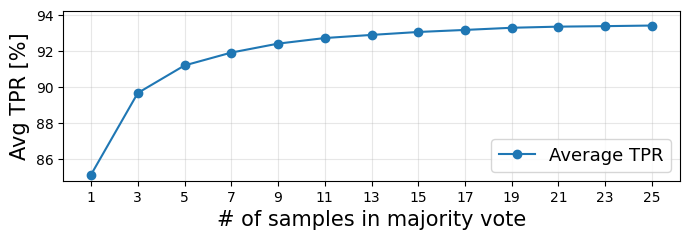

In [13]:
Ks_, tprs, fprs = zip(*rows)
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(Ks_, [t * 100 for t in tprs], 'o-', label='Average TPR')
ax.set_ylim(84.8, 94.2) # the limits are set for visualization purposes and not to suggest that the TPR is expected to be in this range for all datasets.
ax.set_xlabel('# of samples in majority vote', fontsize=15)
ax.set_ylabel('Avg TPR [%]', fontsize=15)
ax.set_xticks(Ks_); ax.grid(alpha=0.3); ax.legend(fontsize=13, loc='lower right')
fig.tight_layout(); fig.savefig('majority_voting_ourfe_tpr.png', dpi=120)
print('saved majority_voting_ourfe_tpr.png  | single-probe baseline: '
      f'TPR={TPR*100:.1f}%  FPR={FPR*100:.2f}%')

saved majority_voting_ourfe_fpr.png  | single-probe baseline: TPR=85.1%  FPR=4.61%


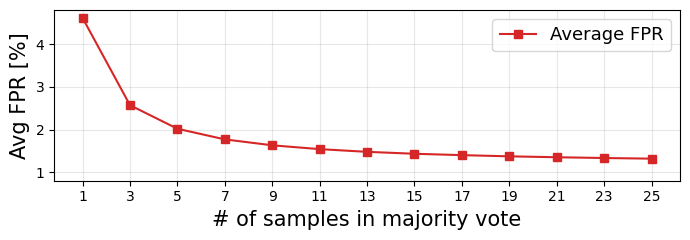

In [14]:
Ks_, tprs, fprs = zip(*rows)
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(Ks_, [f * 100 for f in fprs], 's-', color='tab:red', label='Average FPR')
ax.set_ylim(0.8,4.8)
ax.set_xlabel('# of samples in majority vote', fontsize=15)
ax.set_ylabel('Avg FPR [%]', fontsize=15)
ax.set_xticks(Ks_); ax.grid(alpha=0.3); ax.legend(fontsize=13, loc='upper right')
fig.tight_layout(); fig.savefig('majority_voting_ourfe_fpr.png', dpi=120)
print('saved majority_voting_ourfe_fpr.png  | single-probe baseline: '
      f'TPR={TPR*100:.1f}%  FPR={FPR*100:.2f}%')